# Assignment 2

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [35]:
import json
def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    texts = []
    def collect(node):
        if isinstance(node, str):
            texts.append(node)
        elif isinstance(node, dict):
            for value in node.values():
                collect(value)
        elif isinstance(node, list):
            for item in node:
                collect(item)
    collect(data)
    return texts
texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [17]:
pip install nltk autocorrect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 622.8/622.8 kB 6.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autocorrect: filename=autocorrect-2.6.1-py3-none-any.whl size=622413 sha256=3f58a6b53df6a37034e6ced8ef530c283ae4d7d9208c75adaaa425fd41ed7906
  Stored in directory: /root/.cache/pip/wheels/2c/2b/89/33dd563fa4fa5216ea4b095313a33b7ebc7de8b6cedddfe9f3
Successfully built autocorrect


In [36]:
import re
import string

import nltk
from autocorrect import Speller
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

spell = Speller(lang='en')
lemmatizer = WordNetLemmatizer()
normalization_dict = {
    "u": "you",
    "ur": "your",
    "r": "are",
    "pls": "please",
    "pos": "please",
    "thx": "thanks",
}

protected_words = {
    "oppenheimer", "nolan", "cillian", "murphy",
    "manhattan", "dijkstra", "kruskal",
}


def expand_contractions(text):
    text = text.replace("’", "'").replace("‘", "'")
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "cannot", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"\bit's\b", "it is", text)
    text = re.sub(r"(?<=\w)'re\b", " are", text)
    text = re.sub(r"(?<=\w)'ve\b", " have", text)
    text = re.sub(r"(?<=\w)'ll\b", " will", text)
    text = re.sub(r"(?<=\w)'m\b", " am", text)
    text = re.sub(r"(?<=\w)'d\b", " would", text)
    text = re.sub(r"(?<=\w)'s\b", "", text)
    text = re.sub(r"\b[a-z]\.\s*", "", text)
    return text


def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    processed = []

    for text in texts:
        text = str(text).lower()
        text = expand_contractions(text)
        text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))
        text = re.sub(r'\d+', '', text)
        text = re.sub(r'[^a-z\s]', ' ', text)

        words = word_tokenize(text)
        words = [normalization_dict.get(word, word) for word in words]
        words = [word if word in protected_words or wordnet.synsets(word) else spell(word)
                  for word in words]
        words = [lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos='v'), pos='n') for word in words]

        processed.append(' '.join(words))

    return processed


texts_processed = process_texts(texts)
print(texts_processed)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


['oppenheimer direct by christopher nolan delve into the life of robert oppenheimer the theoretical physicist who lead the development of the atomic bomb the film explore his moral and emotional struggle', 'oppenheimer capture the life of the father of the atomic bomb and his internal conflict after the success of the manhattan project the film complex narrative reflect on the cost of scientific achievement', 'in oppenheimer cillian murphy deliver a rivet performance a the conflict physicist who grapple with the consequence of his groundbreaking work on the atomic bomb under the weight of global politics and ethic', 'oppenheimer be a cinematic exploration of ambition guilt and responsibility through stun visuals and a think provoke story nolan bring the life of the brilliant but haunt physicist to the big screen', 'duck be versatile waterfowl know for their adaptability in freshwater and coastal habitat with web foot and waterproof feather they be excellent swimmer migrate long distanc

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [42]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 93.4 MB/s  0:00:00


In [46]:
import numpy as np
import gensim.downloader as api
model = api.load('glove-wiki-gigaword-100')


def calculate_word2vec_similarity(texts_processed, center=True):
    """
    Cosine similarity between texts represented as IDF-weighted
    averages of word embeddings.

    Args:
        texts_processed (list): list of texts, processed in previous task.
        center (bool): subtract the mean vector so that unrelated texts
                       get values near 0 instead of a high baseline.

    Returns:
        list: n x n matrix of cosine similarity scores.
    """
    docs = [
        [w for w in text.split() if w not in stop_words and w in model]
        for text in texts_processed
    ]

    # IDF over the documents
    n = len(docs)
    df = {}
    for doc in docs:
        for w in set(doc):
            df[w] = df.get(w, 0) + 1
    idf = {w: np.log((n + 1) / (c + 1)) + 1 for w, c in df.items()}

    # Weighted average of word vectors for each text
    vectors = []
    for doc in docs:
        if not doc:
            vectors.append(np.zeros(model.vector_size))
            continue
        weights = np.array([idf[w] for w in doc])
        vecs = np.array([model[w] for w in doc])
        vectors.append((weights[:, None] * vecs).sum(axis=0) / weights.sum())

    V = np.array(vectors)
    if center:
        V = V - V.mean(axis=0)

    norms = np.linalg.norm(V, axis=1, keepdims=True)
    V = np.divide(V, norms, out=np.zeros_like(V), where=norms != 0)

    return (V @ V.T).tolist()


cosine_matrix_w2v = calculate_word2vec_similarity(texts_processed)
print(cosine_matrix_w2v)

[[1.0000000000000002, 0.4258585103794776, 0.4678289861577346, 0.35478983093060146, -0.4512198620640548, -0.35055032706837524, -0.47010871613689875, -0.17685758025474302, -0.28720521231694257, -0.20383134479857612], [0.4258585103794776, 1.0000000000000004, 0.13165434047963415, 0.06989022441519714, -0.558585652159571, -0.3687828282041331, -0.48658027477841087, 0.073908718233545, -0.24623589699245932, 0.25602730086009917], [0.4678289861577346, 0.13165434047963415, 0.9999999999999999, 0.24043025144699787, -0.31667717058042344, -0.1970071343243725, -0.2875203726274686, -0.32438500380248747, -0.15385039724038152, -0.2946540586821505], [0.35478983093060146, 0.06989022441519714, 0.24043025144699787, 1.0000000000000004, -0.1817229037228393, 0.2741163391216998, -0.11453962121400556, -0.44178806766258244, -0.5052763623719346, -0.6413022686852831], [-0.4512198620640548, -0.558585652159571, -0.31667717058042344, -0.1817229037228393, 1.0000000000000002, 0.15928054078720708, 0.5699508071563195, -0.31

## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

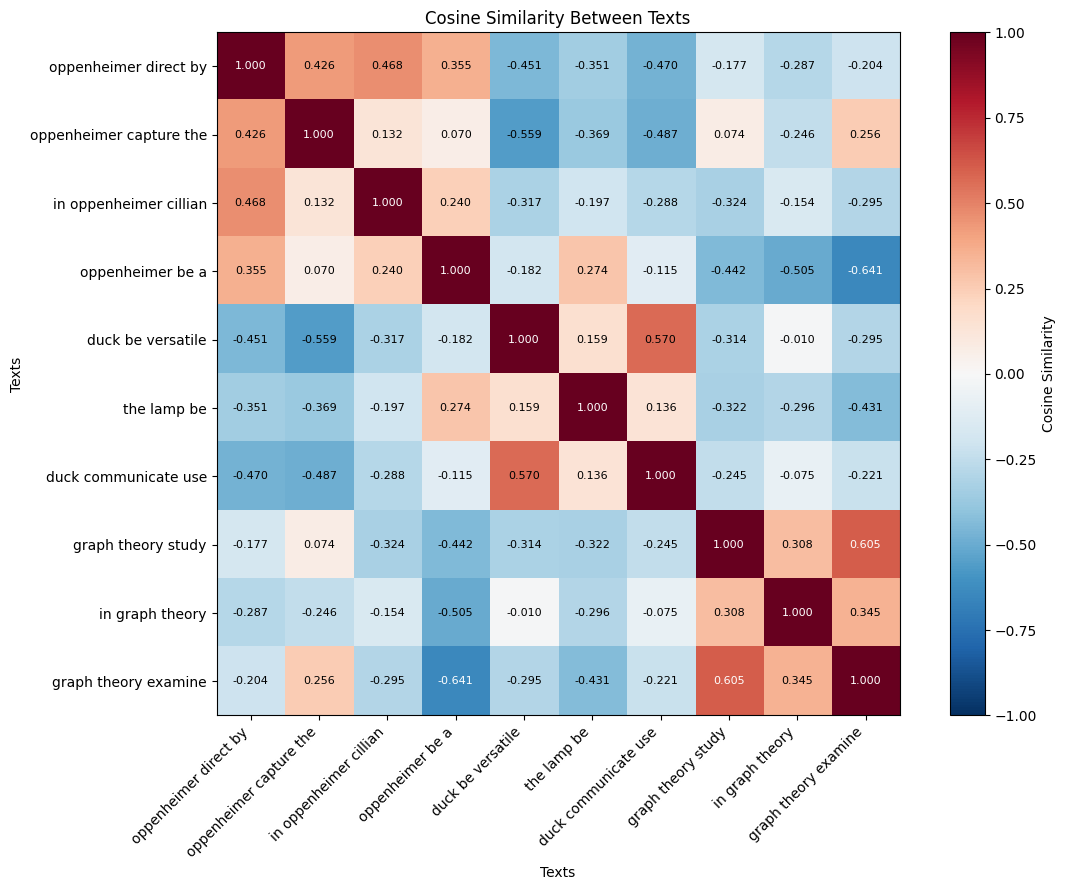

In [48]:
import matplotlib.pyplot as plt
import numpy as np


def visualize_data(cosine_matrix, texts_processed):
    """
    Visualize the cosine similarity matrix from the previous task.

    Args:
        cosine_matrix (list): matrix of cosine similarity scores.
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    matrix = np.array(cosine_matrix)
    labels = [' '.join(text.split()[:3]) for text in texts_processed]

    plt.figure(figsize=(12, 9))
    plt.imshow(matrix, cmap='RdBu_r', vmin=-1, vmax=1)   # changed
    plt.colorbar(label='Cosine Similarity')
    plt.xticks(range(len(labels)), labels, rotation=45, ha='right')
    plt.yticks(range(len(labels)), labels)

    for i in range(len(matrix)):
        for j in range(len(matrix)):
            # white text on dark cells, black on light ones
            color = 'white' if abs(matrix[i, j]) > 0.6 else 'black'   # changed
            plt.text(j, i, f'{matrix[i, j]:.3f}',
                     ha='center', va='center', color=color, fontsize=8)

    plt.title('Cosine Similarity Between Texts')
    plt.xlabel('Texts')
    plt.ylabel('Texts')

    plt.tight_layout()
    plt.show()


visualize_data(cosine_matrix_w2v, texts_processed)   # changed: the word2vec matrix

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

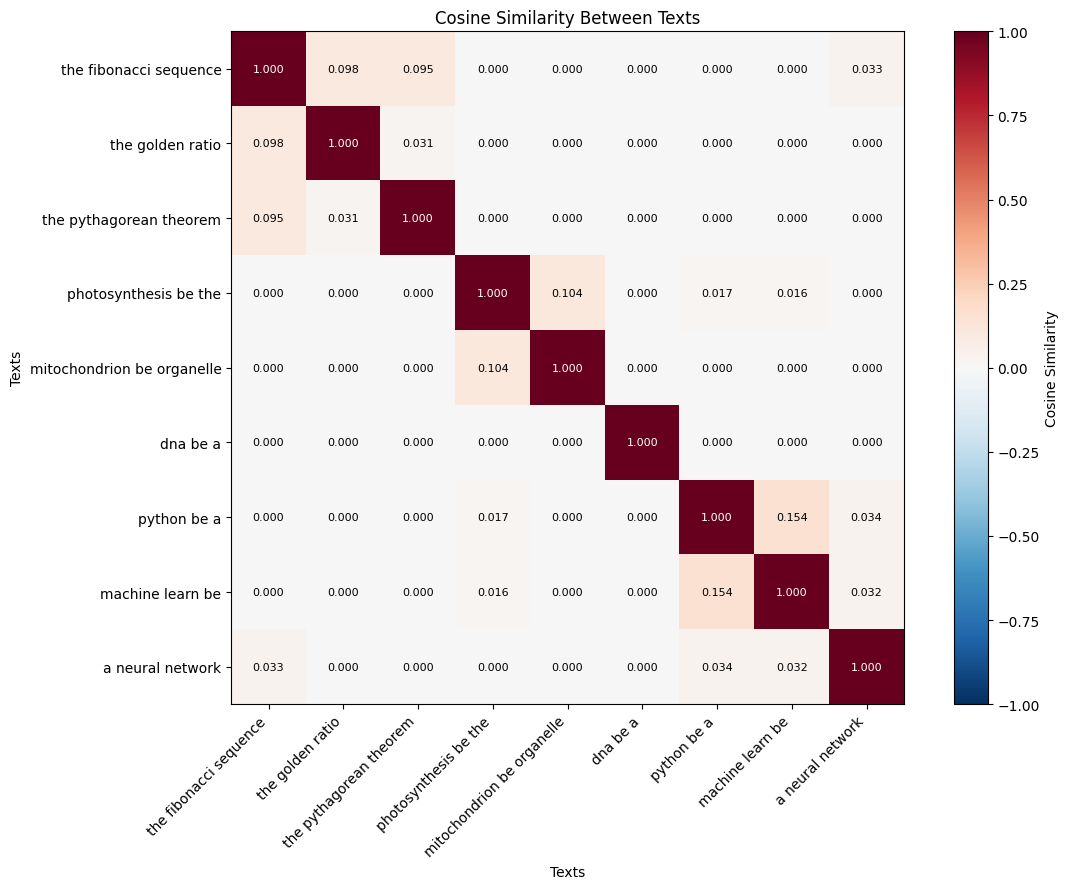

In [49]:
def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    return [
        "The Fibonacci sequence starts with 0 and 1, and every next number is the sum of the two previous ones. It appears in nature, for example in the arrangement of leaves and the spirals of sunflowers.",
        "The golden ratio is an irrational number approximately equal to 1.618. It is closely related to the Fibonacci numbers, because the ratio of consecutive terms approaches it.",
        "The Pythagorean theorem states that in a right triangle the square of the hypotenuse equals the sum of the squares of the other two sides. It is one of the most important results in geometry.",
        "Photosynthesis is the process by which plants use sunlight, water and carbon dioxide to produce glucose and oxygen. It takes place in the chloroplasts of plant cells.",
        "Mitochondria are organelles that produce most of the energy a cell needs. They convert nutrients into ATP, which is why they are called the powerhouses of the cell.",
        "DNA is a molecule that carries the genetic information of living organisms. It has the shape of a double helix built from four types of nucleotides.",
        "Python is a popular programming language known for its simple syntax and readability. It is widely used for data analysis, web development and machine learning.",
        "Machine learning is a field of artificial intelligence in which algorithms learn patterns from data instead of following explicit rules. It is used for classification, prediction and recommendation.",
        "A neural network is a model made of connected layers of artificial neurons. It is trained on examples and can recognize images, understand text and translate languages.",
    ]

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed)

In [51]:
!pip install sentence-transformers

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

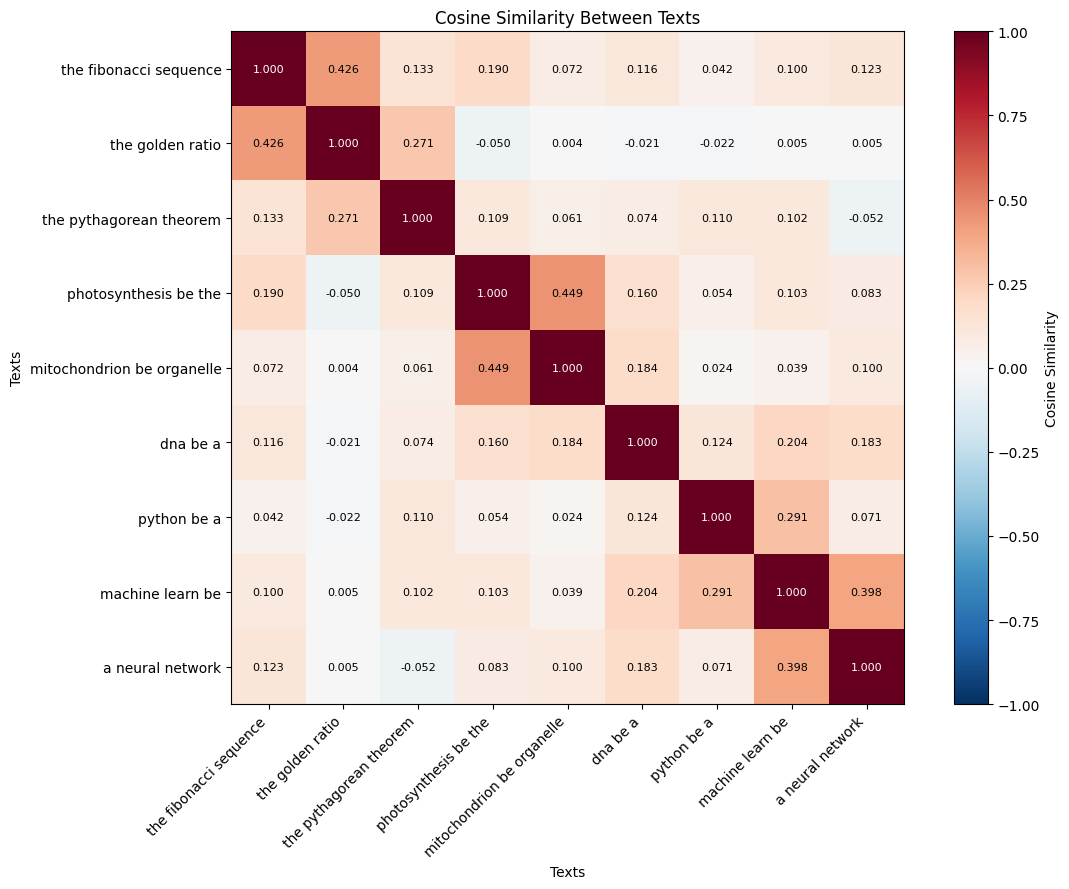

In [52]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(texts)

cosine_matrix_st = cosine_similarity(embeddings).tolist()
visualize_data(cosine_matrix_st, texts_processed)